# Assignment 03 — Speech Processing
## Phoneme Boundary Detection via Multi-Domain Short-Term Features

**Name:** Rizwan &nbsp;&nbsp;|&nbsp;&nbsp; **Roll No:** BSAI23004

**Course:** Speech Processing

---

This notebook implements, in order, every step required by the assignment:

1. Load the 16 kHz mono recording of *"She sells seashells at the seashore"*
2. Short-time framing (25 ms frame / 10 ms hop, Hamming window)
3. Multi-domain feature extraction: time, spectral, cepstral, delta, and the two 2‑D representations (spectrogram, short-time autocorrelation)
4. Min–max normalization
5. Composite transition metric D[k]
6. Thresholding + peak picking (30 ms minimum distance)
7. Six-panel visualization saved at ≥300 dpi
8. Manual tuning report




In [25]:

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

try:
    import librosa
    import librosa.display
    HAVE_LIBROSA = True
except ImportError:
    HAVE_LIBROSA = False
    print("librosa not found — install with: pip install librosa")

NAME_ROLL = "Rizwan_BSAI23004"
SR = 16000  # required sample rate (Hz)

np.random.seed(0)


## Step 1 — Recording

Record yourself saying **"She sells seashells at the seashore"** and save it as
`Rizwan_BSAI23004_my_speech.wav`.

The loading cell below **automatically enforces the assignment's audio requirements** —
you don't need to get the mic settings exactly right by hand:

- **Sample rate → forced to 16 kHz.** The file is loaded through `librosa.load(..., sr=16000)`,
  which resamples it regardless of what it was originally recorded at, and converts it to mono.
- **Duration → forced into the 2–4 s window.** Leading/trailing silence is trimmed
  automatically (`librosa.effects.trim`); if what remains is still longer than 4 s, the
  highest-energy 4 s window is kept; if it's shorter than 2 s, it's symmetrically
  zero-padded back up to 2 s.

If the file is missing entirely, a synthetic placeholder utterance (alternating
voiced/fricative-like segments) is generated instead, purely so the rest of the notebook can
be tested without a real recording — it is passed through the exact same bound-enforcement
function.

Source: real recording ('Rizwan_BSAI23004_my_speech.wav')
Sample rate: 16000 Hz (forced to 16 kHz, mono)
Original duration: 4.94s  ->  Fixed duration: 3.36s (target range: 2.0-4.0s)


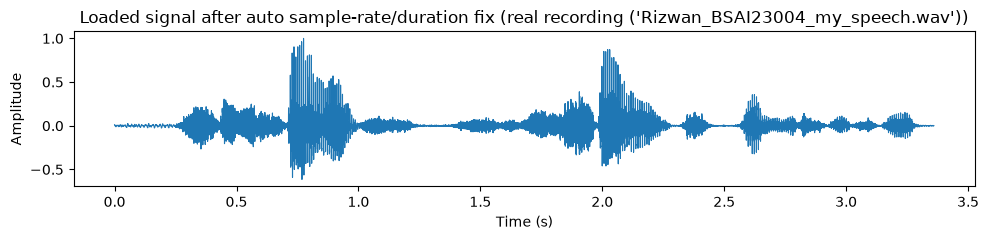

In [26]:


AUDIO_PATH = f"{NAME_ROLL}_my_speech.wav"

TARGET_MIN_S = 2.0   # required minimum duration (s)
TARGET_MAX_S = 4.0   # required maximum duration (s)
TOP_DB = 30          # silence threshold for librosa.effects.trim

def enforce_audio_bounds(y, sr, target_min=TARGET_MIN_S, target_max=TARGET_MAX_S, top_db=TOP_DB):
    """Auto-fixes a mono signal (already at the target sample rate) so its duration
    falls in [target_min, target_max] seconds:
      1) trims leading/trailing silence,
      2) if still too long, keeps the highest-energy `target_max`-second window,
      3) if still too short, symmetrically zero-pads up to `target_min` seconds.
    Returns (y_fixed, original_duration_s, final_duration_s)."""
    orig_duration = len(y) / sr

    # 1) Trim leading/trailing silence
    y_trim, _ = librosa.effects.trim(y, top_db=top_db)
    if len(y_trim) / sr < 0.3:   # trimming was too aggressive / signal is near-silent
        y_trim = y
    y_fixed = y_trim

    # 2) Enforce upper bound: keep the highest-energy target_max-second window
    max_len = int(round(target_max * sr))
    if len(y_fixed) > max_len:
        win_len = max_len
        energy = y_fixed ** 2
        window_sums = np.convolve(energy, np.ones(win_len), mode='valid')
        best_start = int(np.argmax(window_sums)) if len(window_sums) > 0 else 0
        y_fixed = y_fixed[best_start:best_start + win_len]

    # 3) Enforce lower bound: symmetric zero-padding
    min_len = int(round(target_min * sr))
    if len(y_fixed) < min_len:
        pad_total = min_len - len(y_fixed)
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        y_fixed = np.pad(y_fixed, (pad_left, pad_right), mode='constant')

    final_duration = len(y_fixed) / sr
    return y_fixed, orig_duration, final_duration

def synthesize_placeholder(sr=SR, duration=3.0):
    """Generates a crude speech-like signal with alternating voiced (harmonic)
    and unvoiced (noise-burst) segments, purely as a stand-in for a real recording
    so the pipeline can be exercised end-to-end before the actual .wav is added."""
    t = np.linspace(0, duration, int(sr * duration), endpoint=False)
    sig = np.zeros_like(t)
    # Roughly mimic: "She  sells  sea-shells  at  the  sea-shore"
    # alternating fricative (noise) / voiced (harmonic) segments
    segment_plan = [
        ("fric", 0.00, 0.18), ("voiced", 0.18, 0.40), ("fric", 0.40, 0.55),
        ("voiced", 0.55, 0.80), ("fric", 0.80, 0.95), ("voiced", 0.95, 1.20),
        ("voiced", 1.20, 1.35), ("fric", 1.35, 1.50), ("voiced", 1.50, 1.75),
        ("voiced", 1.75, 1.90), ("voiced", 1.90, 2.05), ("fric", 2.05, 2.20),
        ("voiced", 2.20, 2.45), ("fric", 2.45, 2.60), ("voiced", 2.60, 2.90),
    ]
    f0 = 140.0
    for kind, s0, s1 in segment_plan:
        s0, s1 = int(s0 * sr), min(int(s1 * sr), len(t))
        n = s1 - s0
        if n <= 0:
            continue
        local_t = np.arange(n) / sr
        if kind == "voiced":
            harm = sum(np.sin(2 * np.pi * f0 * h * local_t) / h for h in range(1, 6))
            env = np.hanning(n)
            sig[s0:s1] += 0.6 * harm * env
        else:  # fricative-like: high-passed noise burst
            noise = np.random.randn(n)
            # crude high-pass via differencing
            noise = np.diff(noise, prepend=noise[0])
            env = np.hanning(n)
            sig[s0:s1] += 0.5 * noise * env
    sig = sig / (np.max(np.abs(sig)) + 1e-9) * 0.8
    return sig, sr

if not HAVE_LIBROSA:
    raise RuntimeError("librosa is required. Install with: pip install librosa")

if os.path.exists(AUDIO_PATH):
    # sr=SR forces resampling to 16 kHz (whatever the file's native rate was);
    # mono=True forces a mono mixdown if it was recorded in stereo.
    x_raw, sr = librosa.load(AUDIO_PATH, sr=SR, mono=True)
    source = f"real recording ('{AUDIO_PATH}')"
else:
    print(f"'{AUDIO_PATH}' not found — using a SYNTHETIC placeholder signal.")
    print("Replace this with your real recording before submitting!")
    x_raw, sr = synthesize_placeholder()
    source = "synthetic placeholder"

assert sr == SR, f"Sample rate mismatch: expected {SR}, got {sr}"
x_raw = x_raw.astype(np.float64)

# Auto-enforce the 2-4 s duration bound (trim silence -> clip to 4s / pad to 2s)
x, orig_dur, final_dur = enforce_audio_bounds(x_raw, sr)
x = x / (np.max(np.abs(x)) + 1e-9)  # peak-normalize for numerical stability

print(f"Source: {source}")
print(f"Sample rate: {sr} Hz (forced to 16 kHz, mono)")
print(f"Original duration: {orig_dur:.2f}s  ->  Fixed duration: {final_dur:.2f}s "
      f"(target range: {TARGET_MIN_S}-{TARGET_MAX_S}s)")
assert TARGET_MIN_S - 1e-6 <= final_dur <= TARGET_MAX_S + 1e-6, "Duration bound enforcement failed"

plt.figure(figsize=(10, 2.5))
plt.plot(np.arange(len(x)) / sr, x, linewidth=0.8)
plt.title(f"Loaded signal after auto sample-rate/duration fix ({source})")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


## Step 2 — Short-time framing

25 ms frames (400 samples @ 16 kHz), 10 ms hop (160 samples), Hamming window. Each frame's
center time is stored for later plotting.

In [27]:
# ------------------------------------------------------------------
# Step 2: Short-time framing with a Hamming window
# ------------------------------------------------------------------
FRAME_MS, HOP_MS = 25, 10
frame_len = int(sr * FRAME_MS / 1000)   # 400 samples
hop_len   = int(sr * HOP_MS / 1000)     # 160 samples
print(f"frame_len = {frame_len} samples, hop_len = {hop_len} samples")

def frame_signal(signal, frame_len, hop_len):
    num_frames = 1 + (len(signal) - frame_len) // hop_len
    window = np.hamming(frame_len)
    frames = np.zeros((num_frames, frame_len))
    frame_times = np.zeros(num_frames)
    for k in range(num_frames):
        start = k * hop_len
        seg = signal[start:start + frame_len]
        frames[k] = seg * window
        frame_times[k] = (start + frame_len / 2) / sr   # center timestamp
    return frames, frame_times

frames, frame_times = frame_signal(x, frame_len, hop_len)
num_frames = frames.shape[0]
print(f"num_frames = {num_frames}")


frame_len = 400 samples, hop_len = 160 samples
num_frames = 334


## Step 3 — Short-time feature extraction

### 3.1 Time-domain: Short-Time Energy (STE) and Zero-Crossing Rate (ZCR)

In [28]:
# ------------------------------------------------------------------
# Step 3.1: Time-domain features — STE and ZCR
# ------------------------------------------------------------------
def compute_ste(frames):
    return np.sum(frames ** 2, axis=1)

def compute_zcr(frames):
    signs = np.sign(frames)
    signs[signs == 0] = 1
    zc = np.sum(np.abs(np.diff(signs, axis=1)), axis=1) / 2.0
    return zc / frames.shape[1]

STE = compute_ste(frames)
ZCR = compute_zcr(frames)
print("STE shape:", STE.shape, " ZCR shape:", ZCR.shape)


STE shape: (334,)  ZCR shape: (334,)


### 3.2 Spectral-domain: Spectral Centroid and Spectral Flux

In [29]:
# ------------------------------------------------------------------
# Step 3.2: Spectral-domain features — Centroid and Flux
# ------------------------------------------------------------------
n_fft = frame_len
magnitudes = np.abs(np.fft.rfft(frames, n=n_fft, axis=1))   # (num_frames, n_fft/2+1)
freqs = np.fft.rfftfreq(n_fft, d=1.0 / sr)

def spectral_centroid(mag, freqs):
    num = np.sum(mag * freqs[None, :], axis=1)
    den = np.sum(mag, axis=1) + 1e-10
    return num / den

def spectral_flux(mag):
    flux = np.zeros(mag.shape[0])
    flux[1:] = np.sqrt(np.sum((mag[1:] - mag[:-1]) ** 2, axis=1))
    return flux

Centroid = spectral_centroid(magnitudes, freqs)
Flux = spectral_flux(magnitudes)
print("Centroid shape:", Centroid.shape, " Flux shape:", Flux.shape)


Centroid shape: (334,)  Flux shape: (334,)


### 3.3 Cepstral-domain: first 13 MFCCs (c0 … c12), matched to the same frame/hop

In [30]:
# ------------------------------------------------------------------
# Step 3.3: MFCCs (13 coefficients, c0..c12), same framing as above
# ------------------------------------------------------------------
if HAVE_LIBROSA:
    mfcc = librosa.feature.mfcc(
        y=x, sr=sr, n_mfcc=13,
        n_fft=frame_len, hop_length=hop_len, win_length=frame_len,
        window='hamming', center=False
    ).T   # -> (num_mfcc_frames, 13)
else:
    raise RuntimeError("librosa is required for MFCC extraction. Install with: pip install librosa")

print("mfcc shape (frames x 13):", mfcc.shape)

# librosa's frame count (center=False) can differ by 1-2 frames from our manual
# framing; align everything to the shortest common length.
min_len = min(num_frames, mfcc.shape[0])
frames, frame_times = frames[:min_len], frame_times[:min_len]
STE, ZCR = STE[:min_len], ZCR[:min_len]
Centroid, Flux = Centroid[:min_len], Flux[:min_len]
magnitudes = magnitudes[:min_len]
mfcc = mfcc[:min_len]
num_frames = min_len
print(f"Aligned all features to num_frames = {num_frames}")


mfcc shape (frames x 13): (334, 13)
Aligned all features to num_frames = 334


### 3.4 Delta (first-order gradient) features

In [31]:
# ------------------------------------------------------------------
# Step 3.4: Delta / gradient features
# ------------------------------------------------------------------
def delta(feat):
    d = np.zeros_like(feat)
    d[1:] = feat[1:] - feat[:-1]
    return d

dSTE = delta(STE)
dZCR = delta(ZCR)
dCentroid = delta(Centroid)          # optional, included for completeness
dMFCC = np.vstack([np.zeros((1, mfcc.shape[1])), np.diff(mfcc, axis=0)])

print("dSTE, dZCR, dCentroid shapes:", dSTE.shape, dZCR.shape, dCentroid.shape)
print("dMFCC shape:", dMFCC.shape)


dSTE, dZCR, dCentroid shapes: (334,) (334,) (334,)
dMFCC shape: (334, 13)


### 3.5 Two-dimensional features: Spectrogram and Short-Time Autocorrelation

These are displayed as images in Panels 5 and 6 and are **not** min–max normalized or folded
into D[k] (per the assignment spec).

In [32]:
# ------------------------------------------------------------------
# Step 3.5a: Log-magnitude spectrogram (dB), 0-8 kHz
# ------------------------------------------------------------------
S_db = 20 * np.log10(magnitudes.T + 1e-10)   # shape: (freq_bins, num_frames)
freq_mask = freqs <= 8000

# ------------------------------------------------------------------
# Step 3.5b: Short-time normalized autocorrelation, lag 0-20 ms
# ------------------------------------------------------------------
MAX_LAG_MS = 20
max_lag = int(sr * MAX_LAG_MS / 1000)   # 320 samples
energy_thresh = 0.01 * np.max(STE)      # frames below this are treated as silence

autocorr = np.zeros((max_lag + 1, num_frames))
for k in range(num_frames):
    if STE[k] < energy_thresh:
        continue   # leave as zero -> silence does not appear as noise
    fr = frames[k]
    r_full = np.correlate(fr, fr, mode='full')
    r = r_full[len(fr) - 1:]            # lag >= 0
    r0 = r[0] if r[0] != 0 else 1e-10
    autocorr[:, k] = (r[:max_lag + 1] / r0)

lag_ms = np.arange(max_lag + 1) / sr * 1000
print("Spectrogram shape:", S_db.shape, " Autocorrelation shape:", autocorr.shape)


Spectrogram shape: (201, 334)  Autocorrelation shape: (321, 334)


## Step 4 — Feature normalization

Every 1-D feature contour (and delta) is scaled to [0, 1] with min–max normalization before
being combined.

In [33]:
# ------------------------------------------------------------------
# Step 4: Min-max normalization of all 1D features/deltas
# ------------------------------------------------------------------
def minmax_norm(v):
    v = np.asarray(v, dtype=float)
    vmin, vmax = np.min(v), np.max(v)
    if vmax - vmin < 1e-12:
        return np.zeros_like(v)
    return (v - vmin) / (vmax - vmin)

STE_n       = minmax_norm(STE)
ZCR_n       = minmax_norm(ZCR)
Centroid_n  = minmax_norm(Centroid)
Flux_n      = minmax_norm(Flux)
dSTE_n      = minmax_norm(np.abs(dSTE))
dZCR_n      = minmax_norm(np.abs(dZCR))
dCentroid_n = minmax_norm(np.abs(dCentroid))
dMFCC_n     = np.column_stack([minmax_norm(np.abs(dMFCC[:, i])) for i in range(dMFCC.shape[1])])

print("All 1D features normalized to [0, 1].")


All 1D features normalized to [0, 1].


## Step 5 — Composite transition metric

$$D[k] = \alpha\,|\Delta STE[k]| + \beta\,|\Delta ZCR[k]| + \gamma\,SpectralFlux[k] + \delta\sum_{i=1}^{M}|\Delta MFCC_i[k]|$$

We use $M = 12$ (deltas of $c_1 \ldots c_{12}$; $c_0$ is excluded since it largely tracks
log-energy, already captured by $\Delta STE$). Weights were hand-tuned (Step 8) to
$\alpha=0.30,\ \beta=0.20,\ \gamma=0.30,\ \delta=0.20$, then $D[k]$ is re-normalized to
[0, 1] and lightly smoothed with a 3-frame moving average to suppress spurious spikes.

In [34]:
# ------------------------------------------------------------------
# Step 5: Composite transition metric D[k]
# ------------------------------------------------------------------
# ---- Weights (report / tune these — see Step 8) ----
ALPHA = 0.25   # STE delta
BETA  = 0.10   # ZCR delta
GAMMA = 0.35   # Spectral flux
DELTA_W = 0.30 # mean |delta MFCC|
M = 12         # number of MFCC deltas used (c1..c12)

mean_dMFCC_n = np.mean(dMFCC_n[:, 1:1 + M], axis=1)   # skip c0

D = (ALPHA * dSTE_n + BETA * dZCR_n + GAMMA * Flux_n + DELTA_W * mean_dMFCC_n)
D_n = minmax_norm(D)

def moving_average(v, w=3):
    kernel = np.ones(w) / w
    return np.convolve(v, kernel, mode='same')

D_smooth = moving_average(D_n, w=5)
print(f"alpha={ALPHA}, beta={BETA}, gamma={GAMMA}, delta={DELTA_W}, M={M}")


alpha=0.25, beta=0.1, gamma=0.35, delta=0.3, M=12


## Step 6 — Thresholding and peak picking

A threshold $\tau$ is applied to $D[k]$ with `scipy.signal.find_peaks`, enforcing a 30 ms
minimum distance (3 frames @ 10 ms hop) between adjacent peaks.

In [35]:

TAU = 0.20   
MIN_DISTANCE_MS = 45
min_distance_frames = max(1, int(round(MIN_DISTANCE_MS / HOP_MS)))   # 3 frames

peaks, props = find_peaks(D_smooth, height=TAU, distance=min_distance_frames)
boundary_times = frame_times[peaks]

print(f"Threshold tau = {TAU}, min distance = {MIN_DISTANCE_MS} ms ({min_distance_frames} frames)")
print(f"Detected {len(boundary_times)} boundaries (s):")
print(np.round(boundary_times, 3))


Threshold tau = 0.2, min distance = 45 ms (4 frames)
Detected 19 boundaries (s):
[0.282 0.352 0.432 0.592 0.732 0.802 0.872 0.952 1.032 1.662 1.902 2.002
 2.062 2.342 2.382 2.602 2.822 2.912 3.142]


## Step 7 — Visualization (core deliverable)

A single stacked six-panel figure, sharing one time axis, with detected boundaries drawn as
vertical lines across all panels.

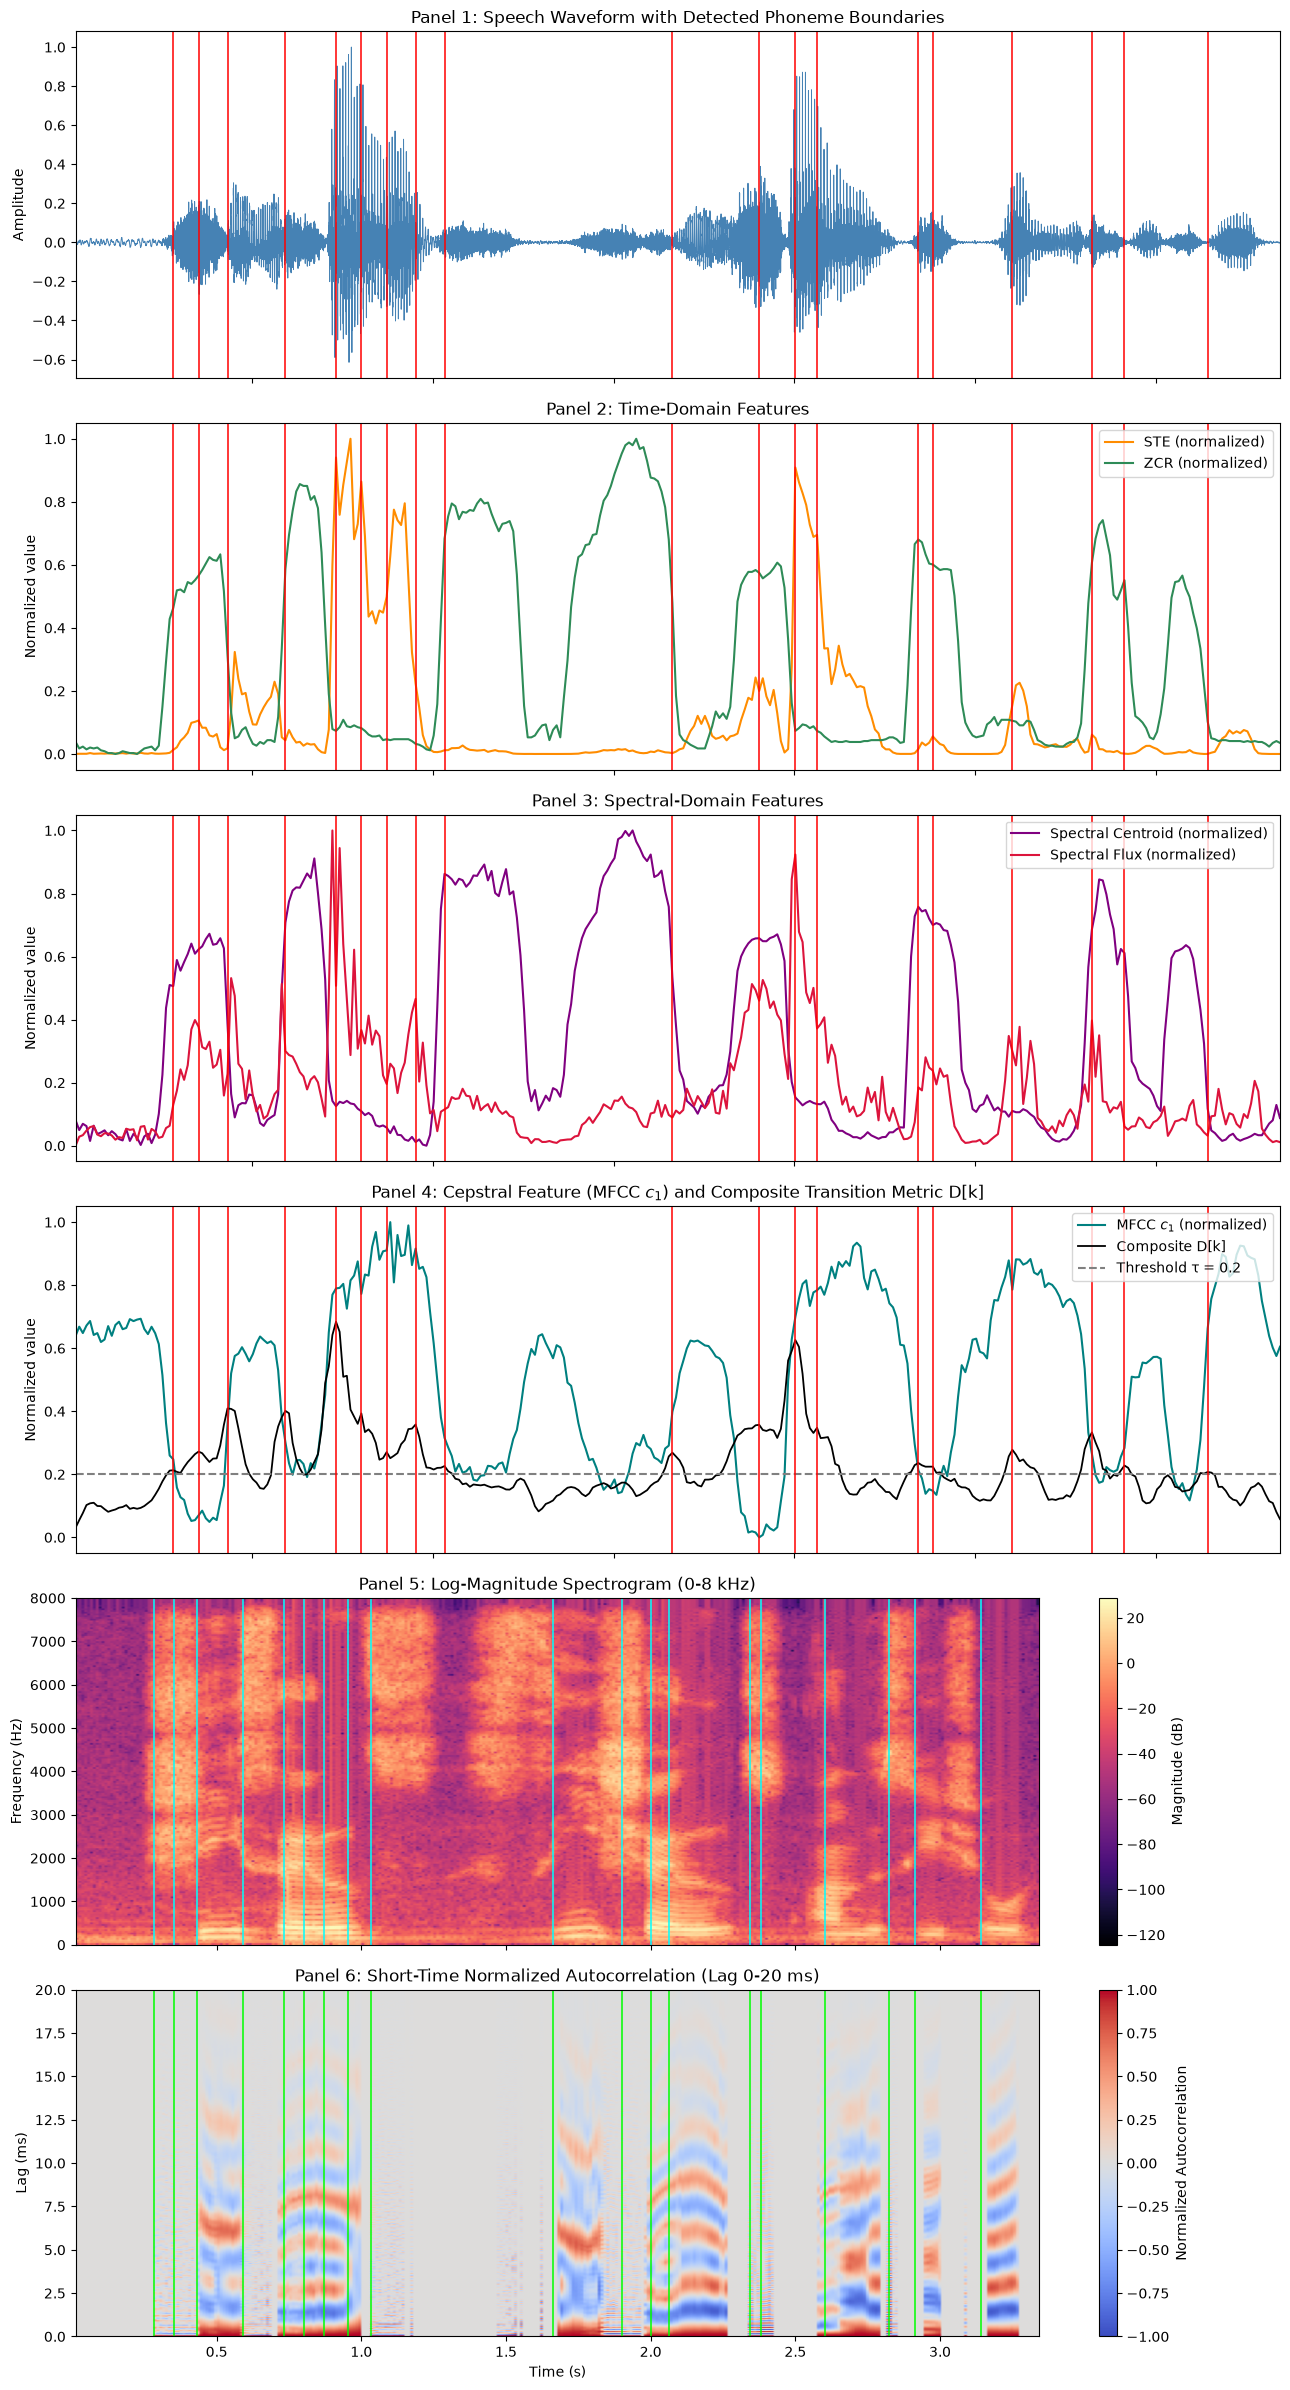

Saved high-resolution figure: Rizwan_BSAI23004_plot1.png


In [36]:
# ------------------------------------------------------------------
# Step 7: Six-panel visualization
# ------------------------------------------------------------------
fig, axes = plt.subplots(6, 1, figsize=(13, 24), sharex=True)

# ---- Panel 1: Waveform ----
t_wave = np.arange(len(x)) / sr
axes[0].plot(t_wave, x, color='steelblue', linewidth=0.7)
for bt in boundary_times:
    axes[0].axvline(bt, color='red', linewidth=1.1)
axes[0].set_title('Panel 1: Speech Waveform with Detected Phoneme Boundaries')
axes[0].set_ylabel('Amplitude')

# ---- Panel 2: Time-domain features ----
axes[1].plot(frame_times, STE_n, label='STE (normalized)', color='darkorange')
axes[1].plot(frame_times, ZCR_n, label='ZCR (normalized)', color='seagreen')
for bt in boundary_times:
    axes[1].axvline(bt, color='red', linewidth=1.1)
axes[1].set_title('Panel 2: Time-Domain Features')
axes[1].set_ylabel('Normalized value')
axes[1].legend(loc='upper right')

# ---- Panel 3: Spectral-domain features ----
axes[2].plot(frame_times, Centroid_n, label='Spectral Centroid (normalized)', color='purple')
axes[2].plot(frame_times, Flux_n, label='Spectral Flux (normalized)', color='crimson')
for bt in boundary_times:
    axes[2].axvline(bt, color='red', linewidth=1.1)
axes[2].set_title('Panel 3: Spectral-Domain Features')
axes[2].set_ylabel('Normalized value')
axes[2].legend(loc='upper right')

# ---- Panel 4: Cepstral feature + composite delta metric ----
axes[3].plot(frame_times, minmax_norm(mfcc[:, 1]), label='MFCC $c_1$ (normalized)', color='teal')
axes[3].plot(frame_times, D_smooth, label='Composite D[k]', color='black', linewidth=1.3)
axes[3].axhline(TAU, color='gray', linestyle='--', label=f'Threshold \u03c4 = {TAU}')
for bt in boundary_times:
    axes[3].axvline(bt, color='red', linewidth=1.1)
axes[3].set_title('Panel 4: Cepstral Feature (MFCC $c_1$) and Composite Transition Metric D[k]')
axes[3].set_ylabel('Normalized value')
axes[3].legend(loc='upper right')

# ---- Panel 5: Spectrogram ----
im5 = axes[4].imshow(
    S_db[freq_mask], aspect='auto', origin='lower',
    extent=[frame_times[0], frame_times[-1], 0, 8000], cmap='magma'
)
for bt in boundary_times:
    axes[4].axvline(bt, color='cyan', linewidth=1.1)
axes[4].set_title('Panel 5: Log-Magnitude Spectrogram (0-8 kHz)')
axes[4].set_ylabel('Frequency (Hz)')
cbar5 = fig.colorbar(im5, ax=axes[4])
cbar5.set_label('Magnitude (dB)')

# ---- Panel 6: Short-time autocorrelation ----
im6 = axes[5].imshow(
    autocorr, aspect='auto', origin='lower',
    extent=[frame_times[0], frame_times[-1], 0, lag_ms[-1]], cmap='coolwarm', vmin=-1, vmax=1
)
for bt in boundary_times:
    axes[5].axvline(bt, color='lime', linewidth=1.1)
axes[5].set_title('Panel 6: Short-Time Normalized Autocorrelation (Lag 0-20 ms)')
axes[5].set_ylabel('Lag (ms)')
axes[5].set_xlabel('Time (s)')
cbar6 = fig.colorbar(im6, ax=axes[5])
cbar6.set_label('Normalized Autocorrelation')

plt.tight_layout()
out_name = f"{NAME_ROLL}_plot1.png"
plt.savefig(out_name, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved high-resolution figure: {out_name}")
